In [21]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rc('font', family = 'Times New Roman')
plt.rcParams.update({'font.size': 14})

In [25]:
records = { # contabilizando apenas setor privado
    "2021": {
        "total_jobs": 2704676, "total_firms": 198658,
        "n_jobs_by_attempt": [1653316, 696233, 63804],
        "n_jobs_geopy_attempt": 181600
    },
    "2013": {
        "total_jobs": 2871490, "total_firms": 215608,
        "n_jobs_by_attempt": [1669648, 822014, 59734],
        "n_jobs_geopy_attempt": 191941
    }
}

In [20]:
100*(sum([1653316, 696233, 63804])+181600)/2704676

95.94321094282643

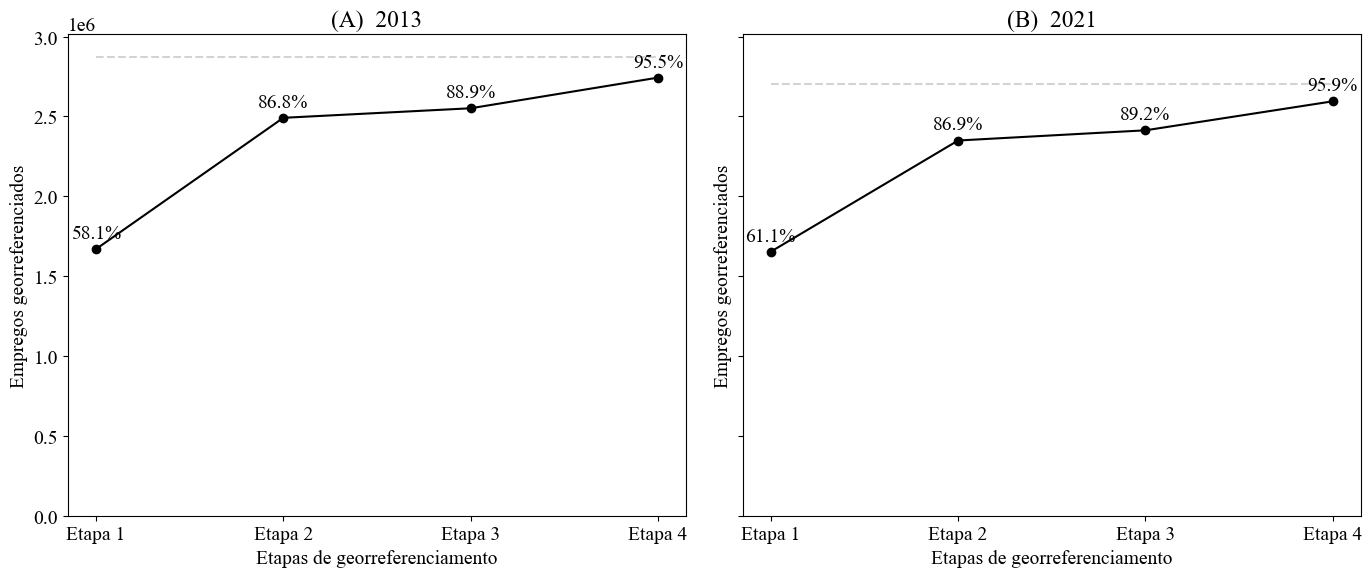

In [26]:
# Função para calcular acumulado e plotar
fig, axs = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for i, year in enumerate(["2013", "2021"]):
    data = records[year]
    total = data["total_jobs"]
    steps = data["n_jobs_by_attempt"] + [data["n_jobs_geopy_attempt"]]
    cumulative = [sum(steps[:j+1]) for j in range(len(steps))]
    step_labels = [f"Etapa {j+1}" for j in range(len(steps))]
    cumulative_percent = [100 * val / total for val in cumulative]

    axs[i].plot(step_labels, cumulative, marker='o', c='black')
    axs[i].hlines(total, xmin=0, xmax=len(step_labels) - 1, colors='lightgray', linestyles='dashed', label='Total')
    for j, (x, y, pct) in enumerate(zip(step_labels, cumulative, cumulative_percent)):
        axs[i].annotate(f"{pct:.1f}%", (j, y), textcoords="offset points", xytext=(0, 8), ha='center')

    letter_label = "A"
    if year=="2021": letter_label = "B"
    axs[i].set_title(f"({letter_label})  {year}")
    axs[i].set_xlabel("Etapas de georreferenciamento")
    axs[i].set_ylabel("Empregos georreferenciados")
    axs[i].grid(False)
    axs[i].set_ylim(0, max(data["total_jobs"] for data in records.values()) * 1.05)

plt.tight_layout()
plt.show()
